In [1]:
# Installs the HuggingFace datasets library
# !pip install datasets

In [2]:
!pip install sentencepiece

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string


from sklearn.model_selection import train_test_split

In [4]:
# Import plotly library
import plotly.graph_objects as go

In [5]:
#---------------------------------------------------------------------------#
# Section: Custom stopwords removal list

# import nltk
# from nltk.corpus import stopwords

# nltk.download('stopwords')

# nltk_stopwords = set(stopwords.words('english'))

# keep_words = {"no", "not", "nor", "ain", "aren", "aren't", "couldn", "couldn't", "didn", "didn't", "doesn", "doesn't", "don", "don't", "hadn",
#               "hadn't", "hasn", "hasn't", "haven", "haven't", "isn", "isn't", "mightn", "mightn't", "mustn", "mustn't", "needn", "needn't", "shan",
#               "shan't", "shouldn", "shouldn't", "wasn", "wasn't", "weren", "weren't", "won", "won't", "wouldn", "wouldn't", "but", "however",
#               "although", "though", "while", "yet", "only", "just", "still", "if", "should", "can", "might", "what", "when", "where", "which",
#               "who", "whom", "why", "how", "very", "more", "most", "own", "same"}

# # Words not in NLTK stopwords that we still want to remove
# extra_remove_words = {"well", "think", "going", "thing", "know", "look"}

# nltk_stopwords.update(extra_remove_words)
# remove_stopwords = nltk_stopwords - keep_words

# print(f"nltk_stopwords sum: {len(nltk_stopwords)}")
# print(f"keep_words sum: {len(keep_words)}")
# print(f"extra_remove_words sum: {len(extra_remove_words)}")
# print(f"final remove_stopwords sum: {len(remove_stopwords)}")

#---------------------------------------------------------------------------#

In [6]:
dataset = load_dataset("ailsntua/QEvasion")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
train_df.head(2)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']
Test columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,annotator1,annotator2,annotator3,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,None,None,None,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,None,None,None,False,False,False,1,Ambivalent,General


In [7]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nLabel distribution (Train):")
print(train_df["clarity_label"].value_counts())

print("\nLabel distribution (Test):")
print(test_df["clarity_label"].value_counts())

Train shape: (3448, 20)
Test shape: (308, 20)

Label distribution (Train):
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

Label distribution (Test):
clarity_label
Ambivalent         206
Clear Reply         79
Clear Non-Reply     23
Name: count, dtype: int64


In [8]:
train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou..."
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou..."
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p..."
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p..."
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l..."
5,Is there a danger of a cold war?,"Well, I hope I get to see Mr. Xi sooner than l..."
6,When will the President meet Mr. Xi?,"Well, I hope I get to see Mr. Xi sooner than l..."
7,How concerned are you about this lack of cons...,It wasn't so much an agreement that we would t...
8,Concerns about the lack of communication betw...,It's not a wedge issue of the Global South. It...
9,Inquiry about the reaction of Kyiv regarding ...,It's not a wedge issue of the Global South. It...


# **Data Cleaning**

In [9]:
def drop_conflicting_labels(df, name):
    # Find (question, answer) pairs with conflicting clarity labels across different annotators
    label_counts = df.groupby(["question", "interview_answer"])["clarity_label"].nunique()

    conflicting_pairs = label_counts[label_counts > 1].reset_index()
    conflicting_pairs.columns = ["question", "interview_answer", "unique_label_count"]

    print(f"Number of (question, answer) pairs with conflicting labels: {len(conflicting_pairs)}\n")

    # Drop (question, answer) pairs with conflicting clarity labels from the dataframe
    print(f"{name} size before dropping conflicting pairs: {len(df)}")

    df_clean = df.groupby(["question", "interview_answer"]).filter(
        lambda x: x["clarity_label"].nunique() == 1
    ).reset_index(drop=True)

    print(f"{name} size after dropping conflicting pairs: {len(df_clean)}\n")
    return df_clean

In [10]:
train_df = drop_conflicting_labels(train_df, "train_df")

Number of (question, answer) pairs with conflicting labels: 12

train_df size before dropping conflicting pairs: 3448
train_df size after dropping conflicting pairs: 3424



In [11]:
# test_df = drop_conflicting_labels(test_df, name="test_df")

In [12]:
def drop_inaudible(df, name):
    # Drop rows where inaudible = True
    print(f"Number of inaudible rows: {df['inaudible'].sum()}\n")

    print(f"{name} size before dropping inaudible rows: {len(df)}")

    df_clean = df[df["inaudible"] == False].reset_index(drop=True)

    print(f"{name} size after dropping inaudible rows: {len(df_clean)}\n")
    return df_clean

In [13]:
train_df = drop_inaudible(train_df, name="train_df")

Number of inaudible rows: 45

train_df size before dropping inaudible rows: 3424
train_df size after dropping inaudible rows: 3379



In [14]:
# test_df = drop_inaudible(test_df, name="test_df")

# **Text Preprocessing**

In [15]:
# Text Preprocessing Part only for the columns "question" and "interview_answer"

def text_preprocessing(text):

    # Remove special unicode characters
    text = text.encode("ascii", "ignore").decode("ascii")

    # Remove stopwords
    # text = " ".join([word for word in text.split() if word not in remove_stopwords])

    # Remove extra whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply to both train and test
train_df["question"] = train_df["question"].apply(text_preprocessing)
train_df["interview_answer"] = train_df["interview_answer"].apply(text_preprocessing)

test_df["question"] = test_df["question"].apply(text_preprocessing)
test_df["interview_answer"] = test_df["interview_answer"].apply(text_preprocessing)


train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou..."
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou..."
2,Do you believe the country's slowdown and grow...,"Look, I think China has a difficult economic p..."
3,Are you worried about the meeting between Pres...,"Look, I think China has a difficult economic p..."
4,Is the President's engagement with Asian count...,"Well, I hope I get to see Mr. Xi sooner than l..."
5,Is there a danger of a cold war?,"Well, I hope I get to see Mr. Xi sooner than l..."
6,When will the President meet Mr. Xi?,"Well, I hope I get to see Mr. Xi sooner than l..."
7,How concerned are you about this lack of conse...,It wasn't so much an agreement that we would t...
8,Concerns about the lack of communication betwe...,It's not a wedge issue of the Global South. It...
9,Inquiry about the reaction of Kyiv regarding t...,It's not a wedge issue of the Global South. It...


In [16]:
# Display rows from the train_df where in interview_answer column has 5 or fewer words

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

train_df["answer_word_count"] = train_df["interview_answer"].apply(lambda x: len(x.split()))

train_df_sorted = train_df[train_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(train_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

pd.reset_option("display.max_rows")
pd.reset_option("display.max_colwidth")

,question,interview_answer,answer_word_count,clarity_label
0,"Discussion of defense budget increase, enemy base strike capability, and Japan-U.S. alliance.",No.,1,Clear Reply
1,Inquiring about the belief in an off-ramp for Vladimir Putin.,Yes.,1,Clear Reply
2,"The question asks if the President is willing to get involved militarily to defend Taiwan, if necessary.",Yes.,1,Clear Reply
3,Analysis of the response to China and the current status of cross-Straits relations,No.,1,Ambivalent
4,Are you satisfied with what came out in the communiqu?,Yes.,1,Clear Reply
5,Reasons for the shortened duration of the summit,Yes.,1,Ambivalent
6,Agreement with President Putin's statement regarding the absence of threats or scare tactics,Yes.,1,Clear Reply
7,Virtual summit participation,Yes.,1,Clear Reply
8,Transparency on the coronavirus origins,Yes.,1,Clear Reply
9,Agreement or disagreement with President Obama's view.,Yes.,1,Clear Reply


In [17]:
test_df["answer_word_count"] = test_df["interview_answer"].apply(lambda x: len(x.split()))

test_df_sorted = test_df[test_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(test_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

,question,interview_answer,answer_word_count,clarity_label
0,Do you think the decision by your G-20 counter...,Okay.,1,Ambivalent
1,What kind of punishment would you like to see ...,Okay.,1,Ambivalent
2,"Can we go back to North Korea, Mr. President?",Please.,1,Clear Reply
3,Clarification on the stance towards a nuclear ...,No.,1,Clear Reply
4,Previous conversations with Prime Minister Mal...,On Iran?,2,Clear Non-Reply
5,Permission to direct a question to President Hu.,Of course.,2,Clear Reply
6,Confidence in Republicans holding the House an...,"Yes, I am.",3,Clear Reply
7,Would you campaign for Mike Fitzpatrick?,I already have.,3,Clear Reply
8,"Is that a make-or-break issue for you, in term...",I already have.,3,Ambivalent
9,Reappointment of U.S. Attorney Patrick Fitzgerald,As a special prosecutor?,4,Clear Non-Reply


In [18]:
print(f"train_df size before dropping: {len(train_df)}")

# Drop rows with 0 words in the answer
train_df = train_df[train_df["answer_word_count"] > 0].reset_index(drop=True)

print(f"train_df size after dropping: {len(train_df)}")

train_df size before dropping: 3379
train_df size after dropping: 3379


In [19]:
# print(f"test_df size before dropping: {len(test_df)}")

# # Drop rows with 0 words in the answer
# test_df = test_df[test_df["answer_word_count"] > 0].reset_index(drop=True)

# print(f"test_df size after dropping: {len(test_df)}")

# **EDA part**

In [20]:
print(train_df["president"].unique())
print(f"\nTotal unique presidents: {train_df['president'].nunique()}")

['Joseph R. Biden' 'Donald J. Trump' 'Barack Obama' 'George W. Bush']

Total unique presidents: 4


In [21]:
print(train_df["clarity_label"].unique())

['Clear Reply' 'Ambivalent' 'Clear Non-Reply']


In [22]:
# Plot pie chart showing the overall distribution of clarity labels across all presidents
def plot_label_distribution_pie(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    colors = ["#2196F3", "#FF9800", "#F44336"]

    label_counts = df["clarity_label"].value_counts()
    values = [label_counts[label] for label in labels]

    fig = go.Figure(data=[go.Pie(labels=labels, values=values)])

    fig.update_traces(
        hoverinfo='label+percent',
        texttemplate='%{percent}<br>%{value}',
        textfont_size=20,
        marker=dict(colors=colors, line=dict(color='#000000', width=2))
    )

    fig.update_layout(
        title=dict(
          text="Overall Clarity Label Distribution",
          font=dict(size=24, family="Arial Black")
        ),
        legend_title="Clarity Label"
    )

    fig.show()

plot_label_distribution_pie(train_df)

In [23]:
plot_label_distribution_pie(test_df)

In [24]:
# Table and grouped bar chart showing answer length statistics (average, median, min, max) per clarity label
def print_length_statistics(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    rows = []

    for label in labels:
        subset = df[df["clarity_label"] == label]["interview_answer"]
        lengths = subset.apply(lambda x: len(x.split()))

        rows.append({
            "Label": label,
            "Average Length": round(lengths.mean(), 1),
            "Median": round(lengths.median(), 1),
            "Min": lengths.min(),
            "Max": lengths.max()
        })

    result_df = pd.DataFrame(rows).set_index("Label")
    display(result_df)

    print("\n\n")

    metrics = ["Max", "Average Length", "Median", "Min"]
    colors  = ["#F44336", "#FF9800", "#2196F3", "#FFEB3B"]

    fig = go.Figure(data=[
        go.Bar(
            name=metric,
            x=labels,
            y=[row[metric] for row in rows],
            text=[row[metric] for row in rows],
            textposition="outside",
            marker_color=color
        )
        for metric, color in zip(metrics, colors)
    ])

    fig.update_layout(
        barmode="group",
        title=dict(
            text="Answer Length Statistics per Clarity Label",
            font=dict(size=24, family="Arial Black")
        ),
        yaxis_title="Length (words)",
        legend_title="Metric",
    )

    fig.update_xaxes(
        tickangle=0,
        tickfont=dict(size=12, color="black"),
        title_text="Clarity Label",
        title_standoff=40
    )

    fig.show()

print_length_statistics(train_df)

,Average Length,Median,Min,Max
Label,,,,
Clear Reply,267.9,190.0,1,1592
Ambivalent,327.9,241.0,1,2117
Clear Non-Reply,136.0,40.0,1,1407


# **DeBERTA Tokenizer SetUp**

In [25]:
from transformers import AutoTokenizer

# Load the DeBERTA tokenizer.
print('Loading DeBERTA tokenizer...')
tokenizer = AutoTokenizer.from_pretrained('microsoft/deberta-v3-base')

Loading DeBERTA tokenizer...


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

In [26]:
label_map = {
    "Clear Non-Reply": 0,
    "Ambivalent": 1,
    "Clear Reply": 2
}

train_df["clarity_label_encoded"] = train_df["clarity_label"].map(label_map)
test_df["clarity_label_encoded"] = test_df["clarity_label"].map(label_map)


print(train_df["clarity_label_encoded"].value_counts())
print("\n")
print(test_df["clarity_label_encoded"].value_counts())

clarity_label_encoded
1    2001
2    1029
0     349
Name: count, dtype: int64


clarity_label_encoded
1    206
2     79
0     23
Name: count, dtype: int64


In [27]:
# Find the max length in tokens for the "question" and "interview_answer" columns
max_question_tokens = train_df["question"].apply(
    lambda x: len(tokenizer.encode(x, add_special_tokens=False))
).max()

max_answer_tokens = train_df["interview_answer"].apply(
    lambda x: len(tokenizer.encode(x, add_special_tokens=False))
).max()

print(f"max question length in tokens: {max_question_tokens}")
print(f"max answer length in tokens: {max_answer_tokens}")

max question length in tokens: 97
max answer length in tokens: 2493


In [28]:
# Create combined sentences list
sentences = (train_df["question"] + " [SEP] " + train_df["interview_answer"]).tolist()

max_len = 0
count_over_512 = 0

# For every sentence...
for sent in sentences:

    # Tokenize the text and add `[CLS]` and `[SEP]` tokens.
    input_ids = tokenizer.encode(sent, add_special_tokens=True)

    # Update the maximum sentence length.
    max_len = max(max_len, len(input_ids))

    # Count sequences longer than 512
    if len(input_ids) > 512:
        count_over_512 += 1

print('Max sentence length: ', max_len)
print(f'Sequences longer than 512: {count_over_512} out of {len(sentences)} ({100*count_over_512/len(sentences):.1f}%)')

Max sentence length:  2522
Sequences longer than 512: 958 out of 3379 (28.4%)


# **Custom Truncation & Input Preparation**

In [29]:
#--------------------------------Alternative custom_truncation strategies experimented with---------------------------------#

# #--------------------------------------------------------------------------------------#
# # Custom truncation for combining question and answer into a single DeBERTA input
# # Format: [CLS] question [SEP] answer [SEP]
# # If the question is bigger than 130 tokens we keep only the first 130 (max question token length in train_df is ~100 tokens)
# # If the question is smaller than 130 the remaining space goes to the answer
# # If the answer is longer than the available space we keep only
# # the FIRST available_space tokens from the beginning of the answer
# def custom_truncation(question, answer, tokenizer, max_question_len=130):

#     # Tokenize question and answer separately (without special tokens)
#     question_tokens = tokenizer.encode(question, add_special_tokens=False)
#     answer_tokens = tokenizer.encode(answer, add_special_tokens=False)

#     # Truncate question to max 130 tokens
#     question_tokens = question_tokens[:max_question_len]

#     # Calculate available space for answer
#     # 512 - 3 special tokens ([CLS], [SEP], [SEP]) - question length
#     available_space = 512 - 3 - len(question_tokens)

#     if len(answer_tokens) <= available_space:
#         # Answer is short enough keep it all
#         answer_final = answer_tokens
#     else:
#         # keep only the FIRST available_space tokens
#         answer_final = answer_tokens[:available_space]

#     # Combine: [CLS] question [SEP] answer [SEP]
#     final_tokens = (
#         [tokenizer.cls_token_id] +
#         question_tokens +
#         [tokenizer.sep_token_id] +
#         answer_final +
#         [tokenizer.sep_token_id]
#     )

#     # Verify always 512 or less
#     assert len(final_tokens) <= 512, f"Sequence too long: {len(final_tokens)}"

#     return final_tokens
# #--------------------------------------------------------------------------------------#


# #--------------------------------------------------------------------------------------#
# # Custom truncation for combining question and answer into a single DeBERTA input
# # Format: [CLS] question [SEP] answer [SEP]
# # If the question is bigger than 130 tokens we keep only the first 130 (max question token length in train_df is ~100 tokens)
# # If the question is smaller than 130 the remaining space goes to the answer
# # If the answer is longer than the available space we keep only
# # the LAST available_space tokens from the end of the answer
# def custom_truncation(question, answer, tokenizer, max_question_len=130):

#     # Tokenize question and answer separately (without special tokens)
#     question_tokens = tokenizer.encode(question, add_special_tokens=False)
#     answer_tokens = tokenizer.encode(answer, add_special_tokens=False)

#     # Truncate question to max 130 tokens
#     question_tokens = question_tokens[:max_question_len]

#     # Calculate available space for answer
#     # 512 - 3 special tokens ([CLS], [SEP], [SEP]) - question length
#     available_space = 512 - 3 - len(question_tokens)

#     if len(answer_tokens) <= available_space:
#         # Answer is short enough keep it all
#         answer_final = answer_tokens
#     else:
#         # keep only the LAST available_space tokens
#         answer_final = answer_tokens[-available_space:]

#     # Combine: [CLS] question [SEP] answer [SEP]
#     final_tokens = (
#         [tokenizer.cls_token_id] +
#         question_tokens +
#         [tokenizer.sep_token_id] +
#         answer_final +
#         [tokenizer.sep_token_id]
#     )

#     # Verify always 512 or less
#     assert len(final_tokens) <= 512, f"Sequence too long: {len(final_tokens)}"

#     return final_tokens
# #--------------------------------------------------------------------------------------#

In [30]:
import torch


# Custom truncation for combining question and answer into a single DeBERTA input
# Format: [CLS] question [SEP] answer [SEP]
# If the question is bigger than 130 tokens we keep only the first 130 (max question token length in train_df is ~100 tokens)
# If the question is smaller than 130 the remaining space goes to the answer
# Since answers are very long we split the available space by 2,
# taking the first available_space // 2 tokens from the beginning of the answer
# and the last available_space // 2 tokens from the end of the answer
def custom_truncation(question, answer, tokenizer, max_question_len=130):

    # Tokenize question and answer separately (without special tokens)
    question_tokens = tokenizer.encode(question, add_special_tokens=False)
    answer_tokens = tokenizer.encode(answer, add_special_tokens=False)

    # Truncate question to max 130 tokens
    question_tokens = question_tokens[:max_question_len]

    # Calculate available space for answer
    # 512 - 3 special tokens ([CLS], [SEP], [SEP]) - question length
    available_space = 512 - 3 - len(question_tokens)


    if len(answer_tokens) <= available_space:
        # Answer is short enough keep it all
        answer_final = answer_tokens
    else:
        # Split available space equally between beginning and end of answer
        beginning_length = available_space // 2
        end_length = available_space - beginning_length

        # Get beginning and end of answer
        # Take first + last tokens of answer
        beginning_answer = answer_tokens[:beginning_length]
        end_answer = answer_tokens[-end_length:]
        answer_final = beginning_answer + end_answer

    # Combine: [CLS] question [SEP] answer [SEP]
    final_tokens = (
        [tokenizer.cls_token_id] +
        question_tokens +
        [tokenizer.sep_token_id] +
        answer_final +
        [tokenizer.sep_token_id]
    )

    # Verify always 512 or less
    assert len(final_tokens) <= 512, f"Sequence too long: {len(final_tokens)}"

    return final_tokens


input_ids = []
attention_masks = []

for _, row in train_df.iterrows():

    # Get the final tokens using our custom truncation
    tokens = custom_truncation(row["question"], row["interview_answer"], tokenizer)

    # Create attention mask: 1 for real tokens, 0 for padding tokens
    attention_mask = [1] * len(tokens)

    # Pad the remaining length of the sequence to reach 512 tokens
    padding_len = 512 - len(tokens)
    tokens = tokens + [tokenizer.pad_token_id] * padding_len
    attention_mask = attention_mask + [0] * padding_len

    # Add the encoded input to the list.
    # Unlike the encode_plus function used in the lab code which returns tensors automatically here we must
    # manually convert the tokens list to a PyTorch tensor and add an extra dimension from 1D to 2D
    # that is why we use torch.tensor(tokens).unsqueeze(0)
    input_ids.append(torch.tensor(tokens).unsqueeze(0))

    # And its attention mask (simply differentiates padding from non-padding).
    # We follow the same logic as above with the torch.tensor(attention_mask).unsqueeze(0)
    attention_masks.append(torch.tensor(attention_mask).unsqueeze(0))

# Convert the lists into tensors.
input_ids = torch.cat(input_ids, dim=0)
attention_masks = torch.cat(attention_masks, dim=0)
labels = torch.tensor(train_df["clarity_label_encoded"].values)

print(f"input_ids shape: {input_ids.shape}")
print(f"attention_masks shape: {attention_masks.shape}")
print(f"labels shape: {labels.shape}")

input_ids shape: torch.Size([3379, 512])
attention_masks shape: torch.Size([3379, 512])
labels shape: torch.Size([3379])


In [31]:
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from sklearn.model_selection import train_test_split

# Stratified 85/15 split
train_indices, val_indices = train_test_split(
    range(len(labels)), test_size=0.15, random_state=42, stratify=labels  # the stratify=labels preserves class distribution in both train and validation sets
)

# Defines what the batch will contain
train_dataset = TensorDataset(
    input_ids[train_indices],
    attention_masks[train_indices],
    labels[train_indices]
)

# Defines what the batch will contain
val_dataset = TensorDataset(
    input_ids[val_indices],
    attention_masks[val_indices],
    labels[val_indices]
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

Training samples: 2872
Validation samples: 507


In [32]:
import torch

# GPU SETUP
# If there's a GPU available...
if torch.cuda.is_available():

    # Tell PyTorch to use the GPU.
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 2 GPU(s) available.
We will use the GPU: Tesla T4


In [33]:
# Class weights
# Needed because our dataset is imbalanced

# Helpful links:
# https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html
# https://medium.com/biased-algorithms/mastering-pytorch-to-device-an-advanced-guide-for-efficient-device-management-0290b086f17e
# https://stackoverflow.com/questions/72400142/adding-in-the-weight-parameter-for-pytorchs-cross-entropy-loss-causes-datatype

from sklearn.utils.class_weight import compute_class_weight

train_labels = train_df["clarity_label_encoded"].values

# Compute class weights: higher weight for minority classes
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# torch.tensor() takes the numpy array class_weights that is on CPU and converts it to a PyTorch tensor
# We do this because PyTorch tensors can work on GPU numpy arrays cannot
# Then with .to(device) takes the PyTorch tensor on CPU and moves it to GPU
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print(f"Class weights: {class_weights}")

Class weights: tensor([3.2273, 0.5629, 1.0946], device='cuda:0')


In [34]:
import datetime
import time
from sklearn.metrics import f1_score

# Function to calculate the accuracy of our predictions vs labels
def flat_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)

def format_time(elapsed):
    '''
    Takes a time in seconds and returns a string hh:mm:ss
    '''
    # Round to the nearest second.
    elapsed_rounded = int(round((elapsed)))

    # Format as hh:mm:ss
    return str(datetime.timedelta(seconds=elapsed_rounded))


# Function to calculate the weighted F1 score of our predictions vs labels
# average='weighted' calculates F1 for each class separately and takes the weighted average
# this accounts for class imbalance by giving more weight to classes with more samples
def flat_f1_weighted(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return f1_score(labels_flat, pred_flat, average='weighted')

# Function to calculate the Macro F1 score of our predictions vs labels
# average='macro' calculates F1 for each class separately and takes the average
# this treats all classes equally regardless of their size
def flat_f1_macro(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return f1_score(labels_flat, pred_flat, average='macro')

In [35]:
# optuna is a hyperparameter optimization framework that automatically
# finds the best combination of training parameters by running multiple trials
!pip install optuna
import optuna
from optuna.pruners import MedianPruner

# **Model Training Section**

In [36]:
import random
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

def search_hyperparams(trial):
# def search_hyperparams():

    #-------------------------------------------------------------------------------------#
    # optuna part


    # Section : hyperparameters for optuna to search over

    # optuna suggests a value for each hyperparameter within the given range
    # Each trial gets different values so optuna can learn which combination works best


    # Learning rate: how fast the model updates its weights
    lr = trial.suggest_float("lr", 5e-6, 2e-5, log=True)

    # Batch size: how many samples to process at once during training
    batch_size = trial.suggest_categorical("batch_size", [8])

    # Epochs: how many times to go through the entire training set
    epochs = trial.suggest_int("epochs", 3, 5)

    # Weight decay: penalizes large weights to prevent overfitting
    # higher value = more regularization
    weight_decay = trial.suggest_float("weight_decay", 0.0, 0.1)

    # Warmup ratio: fraction of training steps where lr gradually increases from 0 to lr
    # helps the model stabilize at the beginning of training
    warmup_ratio = trial.suggest_float("warmup_ratio", 0.0, 0.1)
    #-------------------------------------------------------------------------------------#

    #-------------------------------------------------------------------------------------#
    # Hardcoded parameters

    # # Learning rate: how fast the model updates its weights
    # lr = 1.78e-05

    # # Batch size: how many samples to process at once during training
    # batch_size = 8

    # # Epochs: how many times to go through the entire training set
    # epochs = 3

    # # Weight decay: penalizes large weights to prevent overfitting
    # # higher value = more regularization
    # weight_decay = 0.0499

    # # Warmup ratio: fraction of training steps where lr gradually increases from 0 to lr
    # # helps the model stabilize at the beginning of training
    # warmup_ratio = 0.0794
    #-------------------------------------------------------------------------------------#

    # Section : Build DataLoaders with suggested batch_size

    # The DataLoader defines HOW to serve the batches:
    # - Which dataset to use
    # - In what order: RandomSampler (random order every epoch) or SequentialSampler pull out batches sequentially
    # - How many samples per batch: batch_size
    train_dataloader = DataLoader(
        train_dataset,
        sampler = RandomSampler(train_dataset), # Select batches randomly
        batch_size = batch_size
    )

    # For validation the order doesn't matter, so we'll just read them sequentially.
    validation_dataloader = DataLoader(
        val_dataset,
        sampler=SequentialSampler(val_dataset), # Pull out batches sequentially.
        batch_size=batch_size
    )

    # Section: Load a FRESH AutoModelForSequenceClassification model for each trial
    # the pretrained DeBERTA model with a single linear classification layer on top.
    # This ensures each trial starts with clean pretrained weights
    # and is not influenced by the previous trial's training
    model = AutoModelForSequenceClassification.from_pretrained(
        "microsoft/deberta-v3-base",
        num_labels=3, # The number of output labels
        output_attentions=False, # Whether the model returns attentions weights.
        output_hidden_states=False, # Whether the model returns all hidden-states.
        torch_dtype=torch.float32
    )

    # Tell pytorch to run this model on the GPU.
    model.cuda()

    # Section optimizer
    # The optimizer is responsible for updating the model's weights during training
    optimizer = AdamW(model.parameters(), lr=lr, eps=1e-8, weight_decay=weight_decay)

    # Total number of training steps is [number of batches] x [number of epochs].
    total_steps = len(train_dataloader) * epochs

    # Number of steps where lr gradually increases from 0 to lr before decreasing
    warmup_steps = int(total_steps * warmup_ratio)

    # Create the learning rate scheduler to dynamically adjust the learning rate.
    # The scheduler gradually reduces the learning rate from the value of lr to 0 over all training steps
    # so the model makes big updates at the beginning and tiny precise updates at the end
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    # helpful link
    # https://medium.com/@zergtant/use-weighted-loss-function-to-solve-imbalanced-data-classification-problems-749237f38b75
    # We use weighted CrossEntropyLoss to handle class imbalance by penalizing minority classes more
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

    # Section : Training loop part

    # Track best validation weighted F1 to save the best model
    best_val_f1 = 0

    # Store training and validation loss, accuracy, weighted F1 and Macro F1 and timings per epoch
    trial_stats = []

    # Measure the total training time for the whole run.
    total_t0 = time.time()

    print(f"\n{'='*50}")
    print(f"  TRIAL {trial.number} | lr={lr:.2e} | batch={batch_size} | epochs={epochs} | wd={weight_decay:.4f}")
    # print(f"  lr={lr:.2e} | batch={batch_size} | epochs={epochs} | wd={weight_decay:.4f}")
    print(f"{'='*50}")

    for epoch_i in range(epochs):

        # Training Part

        print("")
        print('======== Epoch {:} / {:} ========'.format(epoch_i + 1, epochs))
        print('Training...')

        # Measure how long the training epoch takes.
        t0 = time.time()

        # Reset the total loss for this epoch
        total_train_loss = 0

        # Put the model into training mode. Don't be mislead--the call to
        # `train` just changes the *mode*, it doesn't *perform* the training.
        # `dropout` and `batchnorm` layers behave differently during training
        # vs. test (source: https://stackoverflow.com/questions/51433378/what-does-model-train-do-in-pytorch)
        model.train()

        # For each batch of training data...
        # We split the training set into batches instead of feeding
        # all samples at once for three reasons:
        #
        # 1. Memory: feeding all samples * 512 tokens at once would crash the GPU
        #
        # 2. Speed: with batches the model updates weights more times per epoch
        #    instead of just 1 time per epoch if we don't use batches
        #    This means the model converges to a good solution much faster
        #
        # 3. Generalization: more updates per epoch means:
        #    - The model sees more gradient signals
        #    - It learns smoother and more stable updates
        #    - It generalizes better to unseen data
        for step, batch in enumerate(train_dataloader):

            # Progress update every 40 batches.
            if step % 40 == 0 and not step == 0:
                # Calculate elapsed time in minutes.
                elapsed = format_time(time.time() - t0)

                # Report progress.
                print('  Batch {:>5,}  of  {:>5,}.    Elapsed: {:}.'.format(
                    step, len(train_dataloader), elapsed))


            # Unpack this training batch from our dataloader.
            #
            # As we unpack the batch, we'll also copy each tensor to the GPU using the
            # `to` method.
            #
            # `batch` contains three pytorch tensors:
            #   [0]: input ids
            #   [1]: attention masks
            #   [2]: labels
            b_input_ids  = batch[0].to(device)
            b_input_mask = batch[1].to(device)
            b_labels = batch[2].to(device)


            # Always reset all gradients to zero before each batch
            # PyTorch accumulates gradients by default (adds new on top of old)
            # so we must clear them manually before each backward pass
            # (source: https://stackoverflow.com/questions/48001598/why-do-we-need-to-call-zero-grad-in-pytorch)
            model.zero_grad()

            # Perform a forward pass (evaluate the model on this training batch)
            # I.e. feed batch_size samples to DeBERTA and get back 3 scores per sample
            # one score for each clarity class (Clear Non-Reply, Ambivalent, Clear Reply)
            result = model(
                b_input_ids,
                attention_mask=b_input_mask,
                return_dict=True
            )

            # The "logits" are the output values (raw scores) from the model
            # logits contains the class scores per sample for this batch
            logits = result.logits

            # Compare the model's predicted scores (logits) with the true labels
            # and compute how wrong the model was, giving higher penalty
            # for misclassifying minority classes
            # using Weighted CrossEntropyLoss instead of model's built-in loss
            loss = loss_fn(logits, b_labels)

            # Accumulate the training loss to calculate the average loss at the end
            total_train_loss += loss.item()

            # Perform a backward pass to calculate the gradients
            # I.e. calculate how much each weight contributed to the error
            # so the optimizer knows how to fix them
            loss.backward()

            # If any gradient is too large shrink it down to a safe size
            # so the model does not make a huge update that breaks training
            # 1.0 is the standard value used in the BERT paper
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            # The optimizer updates the model's weights using the gradients
            # calculated by loss.backward()
            optimizer.step()

            # Update the learning rate.
            scheduler.step()

        # Calculate the average loss over all of the batches.
        avg_train_loss = total_train_loss / len(train_dataloader)

        # Measure how long this epoch took.
        training_time = format_time(time.time() - t0)

        print("")
        print("  Average training loss: {0:.2f}".format(avg_train_loss))
        print("  Training epoch took: {:}".format(training_time))

        # Validation Part
        # After the completion of each training epoch, measure our performance on
        # our validation set.

        print("")
        print("Running Validation...")

        t0 = time.time()

        # Put the model in evaluation mode
        model.eval()

        # Tracking variables
        total_eval_loss = 0
        all_preds = []
        all_labels_list = []

        # Evaluate data for one epoch
        for batch in validation_dataloader:

            # Unpack this validation batch from our dataloader.
            #
            # As we unpack the batch, we'll also copy each tensor to the GPU using
            # the `to` method.
            #
            # `batch` contains three pytorch tensors:
            #   [0]: input ids
            #   [1]: attention masks
            #   [2]: labels
            b_input_ids  = batch[0].to(device)
            b_input_mask = batch[1].to(device)
            b_labels = batch[2].to(device)

            # Tell pytorch not to bother with constructing the compute graph during
            # the forward pass, since this is only needed for backprop (training).
            with torch.no_grad():

                # Perform a forward pass (evaluate the model on this validation batch)
                # I.e. feed batch_size samples to DeBERTA and get back 3 scores per sample
                # one score for each clarity class (Clear Non-Reply, Ambivalent, Clear Reply)
                result = model(
                    b_input_ids,
                    attention_mask=b_input_mask,
                    return_dict=True
                )

            # The "logits" are the output values (raw scores) from the model
            # logits contains the class scores per sample for this batch_size
            logits = result.logits

            # Compare the model's predicted scores (logits) with the true labels
            # and compute how wrong the model was, giving higher penalty
            # for misclassifying minority classes
            # using Weighted CrossEntropyLoss instead of model's built-in loss
            loss = loss_fn(logits, b_labels)

            # Accumulate the validation loss.
            total_eval_loss += loss.item()

            # Move logits and labels from GPU to CPU
            logits = logits.detach().cpu().numpy()
            label_ids = b_labels.to('cpu').numpy()

            all_preds.append(logits)
            all_labels_list.append(label_ids)

        # Combine all batches
        all_preds = np.concatenate(all_preds, axis=0)
        all_labels_list = np.concatenate(all_labels_list, axis=0)

        val_f1 = flat_f1_weighted(all_preds, all_labels_list)
        val_f1_macro = flat_f1_macro(all_preds, all_labels_list)

        val_acc = flat_accuracy(all_preds, all_labels_list)

        # Calculate the average loss over all of the batches.
        avg_val_loss = total_eval_loss / len(validation_dataloader)

        # Measure how long the validation run took.
        validation_time = format_time(time.time() - t0)

        print("  Accuracy: {0:.4f}".format(val_acc))
        print("  F1 (weighted):{0:.4f}".format(val_f1))
        print("  Macro F1: {0:.4f}".format(val_f1_macro))
        print("  Valid. Loss:{0:.4f}".format(avg_val_loss))
        print("  Validation took: {:}".format(validation_time))

        # Save stats for this epoch
        trial_stats.append({
            'epoch': epoch_i + 1,
            'Training Loss': avg_train_loss,
            'Valid. Loss': avg_val_loss,
            'Valid. Accur.': val_acc,
            'Valid. F1': val_f1,
            'Valid. Macro F1': val_f1_macro,
            'Training Time': training_time,
            'Validation Time': validation_time
        })

        # Save best model and stats if this is the best epoch so far
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            # Save stats of this trial so we can use them for plots later
            # without needing to retrain
            torch.save(model.state_dict(), 'best_deberta_model.pt')
            # optuna part
            trial.set_user_attr("trial_stats", trial_stats)
            print("  Best model saved! (F1 weighted: {0:.4f})".format(best_val_f1))

        # optuna part
        # Section : Report to optuna for pruning bad trials early
        # trial.report() tells optuna the score at this epoch
        # trial.should_prune() returns True if this trial is doing worse
        # than the median of previous trials so we stop it early to save time
        trial.report(val_f1, epoch_i)
        if trial.should_prune():
            print(f"  Trial {trial.number} pruned at epoch {epoch_i+1}")
            del model
            torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

    print("")
    print("Training complete!")
    print("Total training took {:} (h:mm:ss)".format(format_time(time.time() - total_t0)))
    print("Best Validation F1 (weighted): {0:.4f}".format(best_val_f1))

    # Free GPU memory after each trial so the next trial starts clean
    del model
    torch.cuda.empty_cache()

    return best_val_f1

    # return trial_stats, best_val_f1

In [37]:
# Clear any leftover GPU memory from previous runs
import gc
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()
print(f"GPU memory free: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB")


# Set the seed value all over the place to make this reproducible.
seed_val = 42

random.seed(seed_val)
np.random.seed(seed_val)
torch.manual_seed(seed_val)
torch.cuda.manual_seed_all(seed_val)

#-----------------------------------------------------------------------#
# optuna part
study = optuna.create_study(
    direction="maximize", # maximize weighted F1
    pruner=MedianPruner(n_warmup_steps=1)  # prune bad trials after epoch 1
)

study.optimize(
    search_hyperparams,
    n_trials=5, # number of hyperparameter combinations to try
)
#-----------------------------------------------------------------------#

# trial_stats, best_val_f1 = search_hyperparams()

#-----------------------------------------------------------------------#
# optuna part
# Print best results
print("\n" + "="*50)
print("OPTUNA SEARCH COMPLETE")
print("="*50)
print(f"Best F1 (weighted) : {study.best_trial.value:.4f}")
print(f"Best Params :")
for key, value in study.best_trial.params.items():
    print(f"  {key}: {value}")
#-----------------------------------------------------------------------#

[I 2026-04-27 12:11:59,910] A new study created in memory with name: no-name-999ec900-0193-4619-8e85-18351329ff24
`torch_dtype` is deprecated! Use `dtype` instead!


GPU memory free: 14.44 GB


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight        

...

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight        


  TRIAL 4 | lr=1.92e-05 | batch=8 | epochs=3 | wd=0.0126

======== Epoch 1 / 3 ========
Training...
  Batch    40  of    359.    Elapsed: 0:00:46.
  Batch    80  of    359.    Elapsed: 0:01:33.
  Batch   120  of    359.    Elapsed: 0:02:20.
  Batch   160  of    359.    Elapsed: 0:03:07.
  Batch   200  of    359.    Elapsed: 0:03:54.
  Batch   240  of    359.    Elapsed: 0:04:41.
  Batch   280  of    359.    Elapsed: 0:05:28.
  Batch   320  of    359.    Elapsed: 0:06:14.

  Average training loss: 1.03
  Training epoch took: 0:07:00

Running Validation...
  Accuracy: 0.3333
  F1 (weighted):0.1886
  Macro F1: 0.2955
  Valid. Loss:1.0839
  Validation took: 0:00:27
  Best model saved! (F1 weighted: 0.1886)

======== Epoch 2 / 3 ========
Training...
  Batch    40  of    359.    Elapsed: 0:00:46.
  Batch    80  of    359.    Elapsed: 0:01:33.
  Batch   120  of    359.    Elapsed: 0:02:20.
  Batch   160  of    359.    Elapsed: 0:03:06.
  Batch   200  of    359.    Elapsed: 0:03:53.
  Batch  

[I 2026-04-27 14:18:53,149] Trial 4 finished with value: 0.6846976262974057 and parameters: {'lr': 1.916260719720319e-05, 'batch_size': 8, 'epochs': 3, 'weight_decay': 0.012586999515977793, 'warmup_ratio': 0.0701330298495958}. Best is trial 4 with value: 0.6846976262974057.


  Best model saved! (F1 weighted: 0.6847)

Training complete!
Total training took 0:22:24 (h:mm:ss)
Best Validation F1 (weighted): 0.6847

OPTUNA SEARCH COMPLETE
Best F1 (weighted) : 0.6847
Best Params :
  lr: 1.916260719720319e-05
  batch_size: 8
  epochs: 3
  weight_decay: 0.012586999515977793
  warmup_ratio: 0.0701330298495958


In [38]:
#-----------------------------------------------------------------------#
# optuna part
# Get best trial stats saved during optuna search we saved these during the best trial
best_trial_stats = study.best_trial.user_attrs["trial_stats"]
best_epochs = study.best_trial.params["epochs"]
best_lr = study.best_trial.params["lr"]
best_batch_size = study.best_trial.params["batch_size"]
best_weight_decay = study.best_trial.params["weight_decay"]
best_warmup_ratio = study.best_trial.params["warmup_ratio"]
#-----------------------------------------------------------------------#

#-----------------------------------------------------------------------#
# Hardcoded parameters
# best_epochs = 3
# best_lr = 1.78e-05
# best_batch_size = 8
# best_weight_decay = 0.0499
# best_warmup_ratio = 0.0794
#-----------------------------------------------------------------------#

# # Display floats with two decimal places.
# pd.options.display.precision = 2

# Create a DataFrame from the best trial statistics.
# df_stats = pd.DataFrame(data=trial_stats)
# optuna part
df_stats = pd.DataFrame(data=best_trial_stats)

# Use the 'epoch' as the row index.
df_stats = df_stats.set_index('epoch')

# Display only the most important columns in a clean format
print("\n========== Best Trial Training Summary ==========")
print(f"Best Params:")
print(f"  lr: {best_lr:.2e}")
print(f"  batch_size: {best_batch_size}")
print(f"  epochs: {best_epochs}")
print(f"  weight_decay: {best_weight_decay:.4f}")
print("")
print(df_stats[['Training Loss', 'Valid. Loss', 'Valid. Accur.', 'Valid. F1', 'Valid. Macro F1']].to_string())
print("=" * 56)
print(f"Best F1 (weighted): {df_stats['Valid. F1'].max():.4f} at Epoch {df_stats['Valid. F1'].idxmax()}")


========== Best Trial Training Summary ==========
Best Params:
  lr: 1.92e-05
  batch_size: 8
  epochs: 3
  weight_decay: 0.0126

       Training Loss  Valid. Loss  Valid. Accur.  Valid. F1  Valid. Macro F1
epoch                                                                       
1           1.033976     1.083903       0.333333   0.188555         0.295472
2           0.815047     0.746073       0.648915   0.651610         0.646068
3           0.679817     0.730878       0.692308   0.684698         0.659528
Best F1 (weighted): 0.6847 at Epoch 3


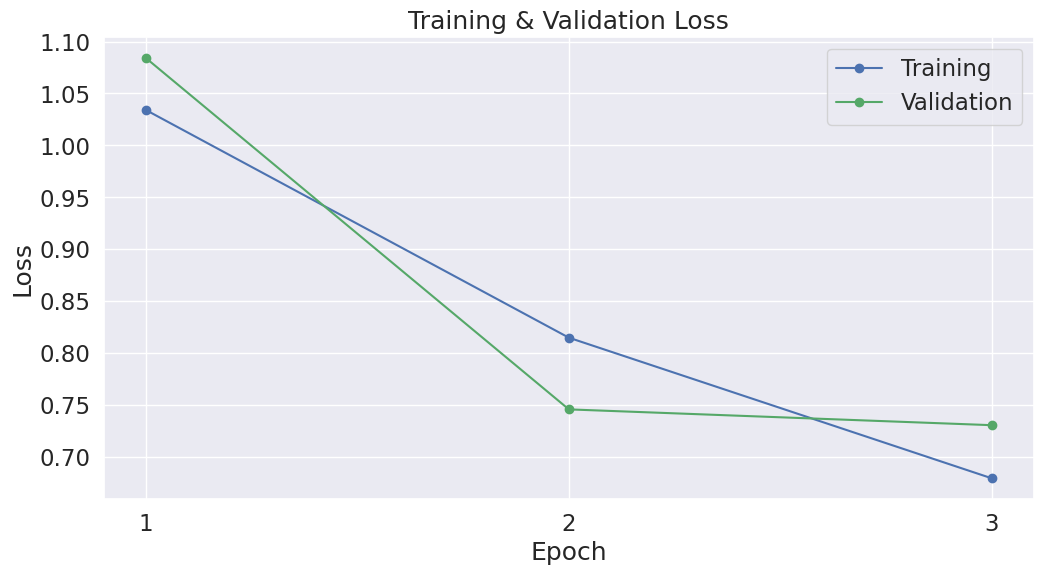

In [39]:
# Visual representation of Training & Validation Loss per epoch
# Helps us see if the model is overfitting
# (training loss goes down but validation loss goes up)

# Use plot styling from seaborn.
sns.set(style='darkgrid')

# Increase the plot size and font size.
sns.set(font_scale=1.5)
plt.rcParams["figure.figsize"] = (12, 6)

# Plot the learning curve.
plt.plot(df_stats['Training Loss'], 'b-o', label="Training")
plt.plot(df_stats['Valid. Loss'], 'g-o', label="Validation")

# Label the plot.
plt.title("Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(1, best_epochs + 1))

plt.show()

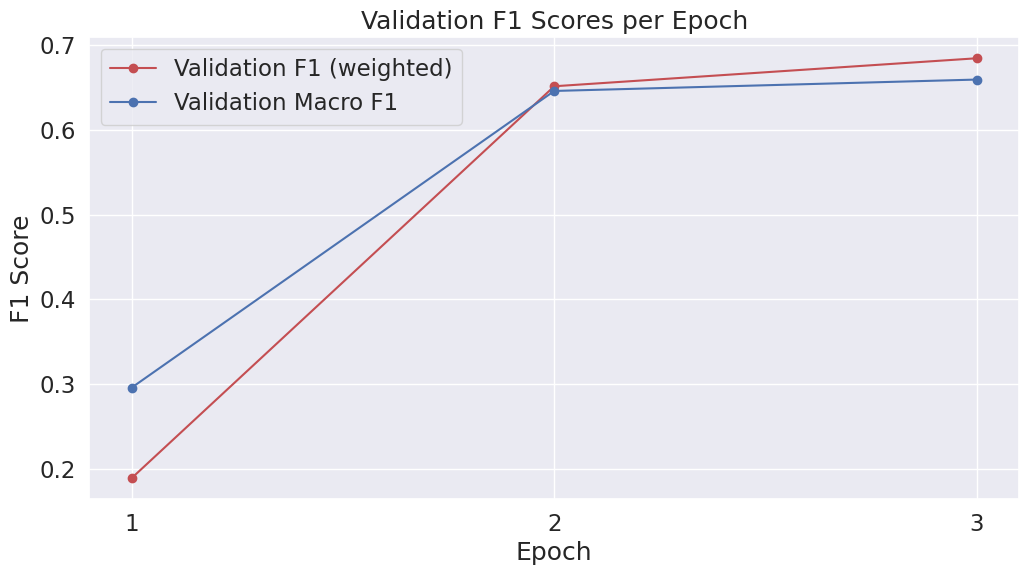

In [40]:
# Visual representation of Validation F1 Scores per Epoch
# Helps us see which epoch had the best weighted F1 and Macro F1
# and whether the model is improving or degrading over time
plt.rcParams["figure.figsize"] = (12, 6)

# Plot both F1 curves
plt.plot(df_stats['Valid. F1'], 'r-o', label="Validation F1 (weighted)")
plt.plot(df_stats['Valid. Macro F1'], 'b-o', label="Validation Macro F1")

# Label the plot.
plt.title("Validation F1 Scores per Epoch")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.legend()
plt.xticks(range(1, best_epochs + 1))

plt.show()

# **Test Set Evaluation**

In [41]:
# Section: Test set


# Load the best model saved during search
print("Loading best model...")

# We load the saved weights back into a fresh AutoModelForSequenceClassification model
model = AutoModelForSequenceClassification.from_pretrained(
    "microsoft/deberta-v3-base",
    num_labels=3, # The number of output labels
    output_attentions=False, # Whether the model returns attentions weights.
    output_hidden_states=False, # Whether the model returns all hidden-states.
    # Unlike BERT and DistilBERT which use Float32 by default,
    # DeBERTA can load in Float16 on some GPUs which causes gradient errors during training.
    # We force Float32 here to ensure stable training
    torch_dtype=torch.float32
)

# Load the best weights saved during search
# map_location=device ensures the model loads correctly on GPU or CPU
model.load_state_dict(torch.load('best_deberta_model.pt', map_location=device))

# Tell pytorch to run this model on the GPU.
model.cuda()

Loading best model...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight        

DebertaV2ForSequenceClassification(
  (deberta): DebertaV2Model(
    (embeddings): DebertaV2Embeddings(
      (word_embeddings): Embedding(128100, 768, padding_idx=0)
      (LayerNorm): LayerNorm((768,), eps=1e-07, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): DebertaV2Encoder(
      (layer): ModuleList(
        (0-11): 12 x DebertaV2Layer(
          (attention): DebertaV2Attention(
            (self): DisentangledSelfAttention(
              (query_proj): Linear(in_features=768, out_features=768, bias=True)
              (key_proj): Linear(in_features=768, out_features=768, bias=True)
              (value_proj): Linear(in_features=768, out_features=768, bias=True)
              (pos_dropout): Dropout(p=0.1, inplace=False)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): DebertaV2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): Layer

In [42]:
# Section : Prepare the test set
# We apply the same tokenization and truncation as the training set

print("Preparing test set...")

test_input_ids = []
test_attention_masks = []

for _, row in test_df.iterrows():

    # Get the final tokens using our custom truncation by calling the custom_truncation function
    # Same logic as training set: Format [CLS] question [SEP] answer [SEP]
    tokens = custom_truncation(row["question"], row["interview_answer"], tokenizer)

    # Create attention mask: 1 for real tokens, 0 for padding tokens
    attention_mask = [1] * len(tokens)

    # Pad the remaining length of the sequence to reach 512 tokens
    padding_len = 512 - len(tokens)
    tokens = tokens + [tokenizer.pad_token_id] * padding_len
    attention_mask = attention_mask + [0] * padding_len

    # Add the encoded input to the list.
    # Unlike the encode_plus function used in the lab code which returns tensors automatically here we must
    # manually convert the tokens list to a PyTorch tensor and add an extra dimension from 1D to 2D
    # that is why we use torch.tensor(tokens).unsqueeze(0)
    test_input_ids.append(torch.tensor(tokens).unsqueeze(0))

    # And its attention mask (simply differentiates padding from non-padding).
    # We follow the same logic as above with the torch.tensor(attention_mask).unsqueeze(0)
    test_attention_masks.append(torch.tensor(attention_mask).unsqueeze(0))

# Convert the lists into tensors
test_input_ids = torch.cat(test_input_ids, dim=0)
test_attention_masks = torch.cat(test_attention_masks, dim=0)

print(f"Test input_ids shape: {test_input_ids.shape}")
print(f"Test attention_masks shape: {test_attention_masks.shape}")

Preparing test set...
Test input_ids shape: torch.Size([308, 512])
Test attention_masks shape: torch.Size([308, 512])


In [43]:
# Section: Create the test DataLoader
# We use SequentialSampler because order matters for submission

# Use the actual labels from the test set
test_labels = torch.tensor(test_df["clarity_label_encoded"].values)

# Defines what the batch will contain
test_dataset = TensorDataset(
    test_input_ids,
    test_attention_masks,
    test_labels # real labels from the test set
)

# Use the same batch size as the best model found in optuna search
# best_batch_size = 8
# optuna part
best_batch_size = study.best_trial.params["batch_size"]

# Create the DataLoader for the test set
# The DataLoader defines HOW to serve the batches:
# - We use SequentialSampler to keep the original order of the test set this is important for the Kaggle submission
test_dataloader = DataLoader(
    test_dataset,
    sampler=SequentialSampler(test_dataset), # Keep original order
    batch_size=best_batch_size
)

In [44]:
# Section : Run predictions on the test set


print(f"\nPredicting labels for {len(test_input_ids):,} test sentences...")

# Put model in evaluation mode
model.eval()

# Tracking variables
all_predictions = []

# Predict
for batch in test_dataloader:

    # Unpack the inputs from our dataloader
    # and copy each tensor to the GPU
    b_input_ids  = batch[0].to(device)
    b_input_mask = batch[1].to(device)

    # Tell pytorch not to bother with constructing the compute graph during
    # the forward pass, since this is only needed for backprop (training).
    with torch.no_grad():

        # Forward pass, calculate logit predictions
        # I.e. feed batch_size samples to DeBERTA and get back 3 scores per sample
        # one score for each clarity class (Clear Non-Reply, Ambivalent, Clear Reply)
        result = model(
            b_input_ids,
            attention_mask=b_input_mask,
            return_dict=True
        )

    # The "logits" are the output values (raw scores) from the model
    # logits contains the class scores per sample for this batch_size
    logits = result.logits

    # Move logits from GPU to CPU and convert to numpy
    logits = logits.detach().cpu().numpy()

    # Store predictions
    all_predictions.append(logits)


Predicting labels for 308 test sentences...


In [45]:
from sklearn.metrics import classification_report


# Section: Convert predictions to labels and evaluate


# Combine the results across all batches
flat_predictions = np.concatenate(all_predictions, axis=0)

# For each sample pick the label with the highest score
# argmax returns the index of the highest score (0, 1 or 2)
flat_predictions = np.argmax(flat_predictions, axis=1).flatten()

# Get the true labels from the test set
true_labels = test_df["clarity_label_encoded"].values

print("\n========== Test Set Evaluation ==========")
print(f"Accuracy: {flat_accuracy(np.vstack(all_predictions), true_labels):.4f}")
print(f"F1 (weighted): {flat_f1_weighted(np.vstack(all_predictions), true_labels):.4f}")
print(f"Macro F1: {flat_f1_macro(np.vstack(all_predictions), true_labels):.4f}")

# Detailed report per class showing precision, recall and F1 for each label
label_names = ["Clear Non-Reply", "Ambivalent", "Clear Reply"]
print("\nClassification Report:")
print(classification_report(true_labels, flat_predictions, target_names=label_names))


========== Test Set Evaluation ==========
Accuracy: 0.6721
F1 (weighted): 0.6612
Macro F1: 0.5630

Classification Report:
                 precision    recall  f1-score   support

Clear Non-Reply       0.40      0.74      0.52        23
     Ambivalent       0.76      0.80      0.78       206
    Clear Reply       0.52      0.32      0.39        79

       accuracy                           0.67       308
      macro avg       0.56      0.62      0.56       308
   weighted avg       0.67      0.67      0.66       308



In [46]:
reverse_label_map = {0: "Clear Non-Reply", 1: "Ambivalent", 2: "Clear Reply"}

predicted_labels = [reverse_label_map[pred] for pred in flat_predictions]

with open("submission_microsoft-deberta-v3-base.csv", "w") as file:
    file.write("Id,Predicted\n")
    for i, prediction in enumerate(predicted_labels):
        file.write(f"{i},{prediction}\n")

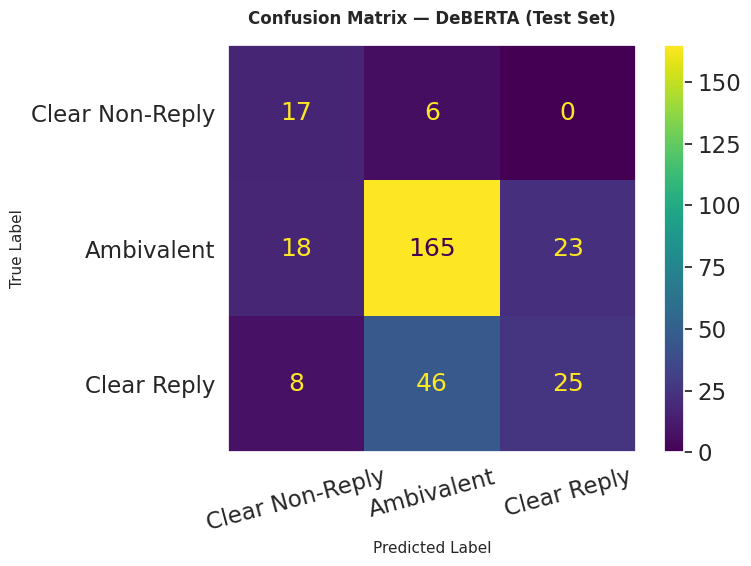


Confusion Matrix (raw counts):
Labels: ['Clear Non-Reply', 'Ambivalent', 'Clear Reply']
[[ 17   6   0]
 [ 18 165  23]
 [  8  46  25]]


In [47]:
# Confusion Matrix Part: DeBERTA Model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

label_names = ["Clear Non-Reply", "Ambivalent", "Clear Reply"]

# Compute the confusion matrix
cm = confusion_matrix(true_labels, flat_predictions)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap="viridis", colorbar=True)

ax.grid(False)

ax.set_title("Confusion Matrix — DeBERTA (Test Set)",
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\nConfusion Matrix (raw counts):")
print(f"Labels: {label_names}")
print(cm)